# 01 · Exploring the Solar-Energy dataset

**Project:** reproduce LSTNet (Lai et al., SIGIR 2018) on Solar-Energy, horizon 24, then test
whether a simple linear model or RevIN changes the picture.

**Questions for this notebook**
1. Is the file what the paper describes (52,560 steps of 10 minutes × 137 PV plants)?
2. Where are the 60/20/20 chronological split boundaries, and which part of the year is each?
3. How different are the plants in scale?
4. How many zeros (nights) and constant plants are there? They affect training and CORR.
5. Is the daily pattern (144 steps) there? What does horizon 24 (4 hours) mean for it?
6. Does the level of a plant change between training and test? The paper's argument for the
   AR component (Sec. 4.6) rests on this, and so does our RevIN improvement.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/solar_AL.txt.gz")         # created by scripts/download_data.sh
FIGS = Path("../results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

STEPS_PER_DAY = 144                             # one step = 10 minutes, 6 per hour * 24 hours
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(0)                  # fixed seed so the random plant picks repeat

## 1 · Load and check the shape

One line per 10 minutes, one comma-separated column per PV plant (power in MW).
The file has no timestamps; the paper says the data is from Alabama, the whole year 2006.

In [2]:
x = np.loadtxt(DATA, delimiter=",")
T, n = x.shape
print(f"shape: {x.shape}  (time steps × plants)")
assert x.shape == (52560, 137), "not the shape the paper reports"
print(f"missing values: {np.isnan(x).sum()}")
print(f"min {x.min():.1f}, max {x.max():.1f} MW")
print(f"{T} steps = {T / STEPS_PER_DAY:.0f} days = {T / STEPS_PER_DAY / 365:.2f} years")

shape: (52560, 137)  (time steps × plants)
missing values: 0
min 0.0, max 88.9 MW
52560 steps = 365 days = 1.00 years


## 2 · Chronological split (60 / 20 / 20)

Same as the authors' code: the boundaries are at 60% and 80% of the time steps.
The data is exactly one year, so the split is also a **season** split: the model trains on
winter to summer and is tested on autumn and early winter.

In [3]:
train_end = int(0.6 * T)
valid_end = int(0.8 * T)
day = lambda step: step / STEPS_PER_DAY        # time step -> day of the year (0 = 1 January)
print(f"train: steps 0 .. {train_end - 1}      days {day(0):.0f} .. {day(train_end):.0f}")
print(f"valid: steps {train_end} .. {valid_end - 1}  days {day(train_end):.0f} .. {day(valid_end):.0f}")
print(f"test : steps {valid_end} .. {T - 1}  days {day(valid_end):.0f} .. {day(T):.0f}")

# With window q = 168 and horizon h = 24, the first usable target is at step q + h - 1.
q, h = 168, 24
print(f"\nq = {q} steps = {q / 6:.0f} hours of input; h = {h} steps = {h / 6:.0f} hours ahead")
print(f"training targets start at step {q + h - 1}, so about {train_end - (q + h - 1)} training windows")

train: steps 0 .. 31535      days 0 .. 219
valid: steps 31536 .. 42047  days 219 .. 292
test : steps 42048 .. 52559  days 292 .. 365

q = 168 steps = 28 hours of input; h = 24 steps = 4 hours ahead
training targets start at step 191, so about 31345 training windows


## 3 · How different are the plants in scale?

Unlike Electricity, all plants are of a similar type, so we expect a much smaller spread.

per-plant maximum: smallest 8.8, median 32.1, largest 88.9 MW
per-plant mean:    smallest 1.61, median 5.75, largest 19.13 MW
ratio largest / smallest mean: 12×


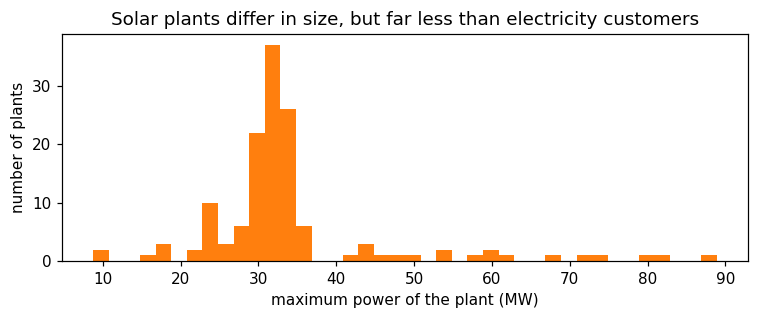

In [4]:
series_max = x.max(axis=0)
series_mean = x.mean(axis=0)
print(f"per-plant maximum: smallest {series_max.min():.1f}, median {np.median(series_max):.1f}, largest {series_max.max():.1f} MW")
print(f"per-plant mean:    smallest {series_mean.min():.2f}, median {np.median(series_mean):.2f}, largest {series_mean.max():.2f} MW")
print(f"ratio largest / smallest mean: {series_mean.max() / series_mean.min():.0f}×")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(series_max, bins=40, color="tab:orange")
ax.set_xlabel("maximum power of the plant (MW)")
ax.set_ylabel("number of plants")
ax.set_title("Solar plants differ in size, but far less than electricity customers")
plt.tight_layout()
plt.show()

## 4 · A few plants: the whole year and one week

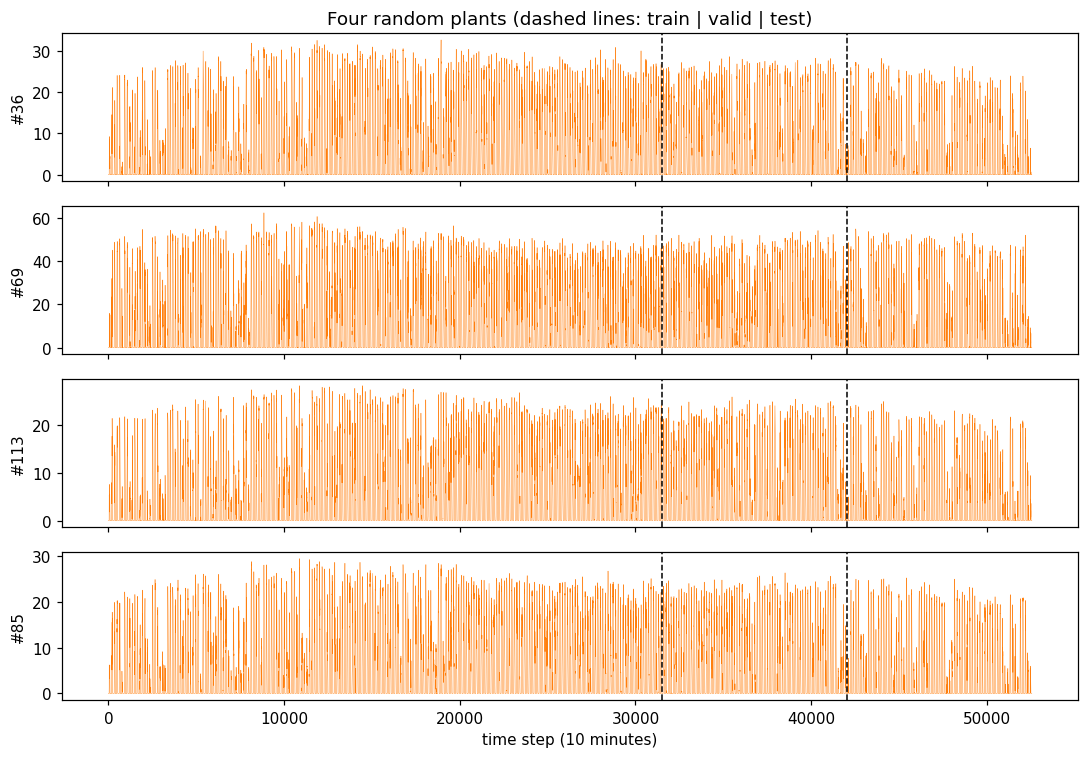

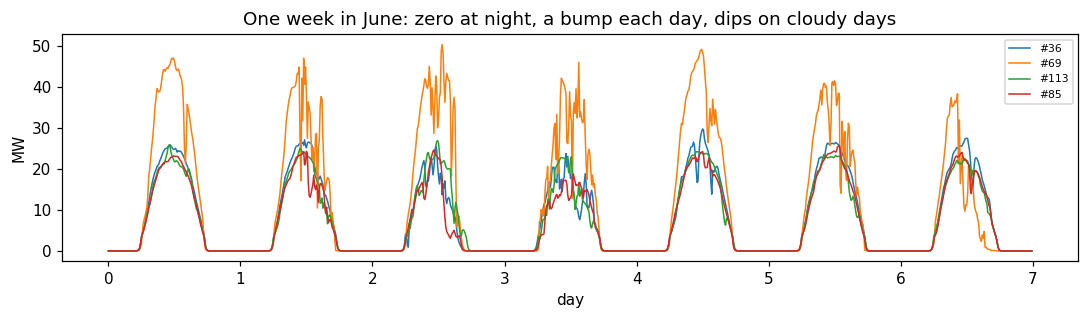

In [5]:
picks = rng.choice(n, size=4, replace=False)
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, j in zip(axes, picks):
    ax.plot(x[:, j], lw=0.3, color="tab:orange")
    ax.axvline(train_end, color="k", ls="--", lw=1)
    ax.axvline(valid_end, color="k", ls="--", lw=1)
    ax.set_ylabel(f"#{j}")
axes[0].set_title("Four random plants (dashed lines: train | valid | test)")
axes[-1].set_xlabel("time step (10 minutes)")
plt.tight_layout()
plt.show()

# One week in June, to see the shape of a single day
start = 160 * STEPS_PER_DAY
week = slice(start, start + 7 * STEPS_PER_DAY)
fig, ax = plt.subplots(figsize=(10, 3))
for j in picks:
    ax.plot(np.arange(7 * STEPS_PER_DAY) / STEPS_PER_DAY, x[week, j], lw=1, label=f"#{j}")
ax.set_xlabel("day")
ax.set_ylabel("MW")
ax.set_title("One week in June: zero at night, a bump each day, dips on cloudy days")
ax.legend(fontsize=7)
plt.tight_layout()
fig.savefig(FIGS / "solar_one_week.png")
plt.show()

## 5 · Zeros, night and constant series

* **Night:** a PV plant produces nothing at night, so many values are exactly 0.
  A model predicting 0 at night is easy; the hard part is the daytime.
* **Constant in test:** a plant with zero variance in the test targets has no defined
  correlation. The authors' code drops such series from the CORR average; we must do the same
  and report how many.

share of all values that are 0: 55.1%
time steps where ALL plants are 0 (night): 49.5%
share of zeros per plant: min 53.6%, max 56.5%
plants constant over the whole year: 0
plants constant over the whole test period: 0


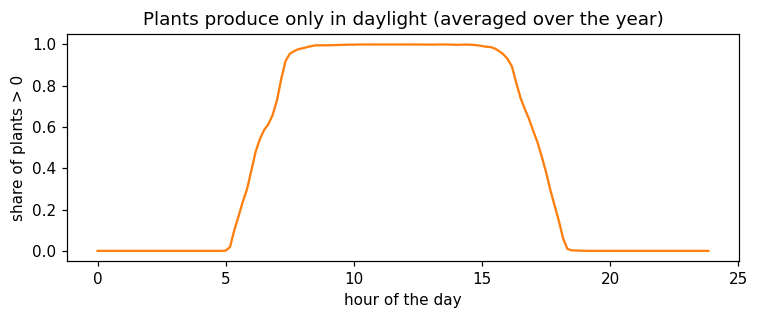

In [6]:
zero_frac = (x == 0).mean(axis=0)
print(f"share of all values that are 0: {(x == 0).mean():.1%}")
all_zero_steps = (x == 0).all(axis=1)
print(f"time steps where ALL plants are 0 (night): {all_zero_steps.mean():.1%}")
print(f"share of zeros per plant: min {zero_frac.min():.1%}, max {zero_frac.max():.1%}")

const = np.where(x.std(axis=0) == 0)[0]
print(f"plants constant over the whole year: {len(const)}")
test = x[valid_end:]
const_test = np.where(test.std(axis=0) == 0)[0]
print(f"plants constant over the whole test period: {len(const_test)}")

# Average share of plants that are producing, per time of day
time_of_day = np.arange(T) % STEPS_PER_DAY
producing = (x > 0).mean(axis=1)
by_time = [producing[time_of_day == k].mean() for k in range(STEPS_PER_DAY)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(STEPS_PER_DAY) / 6, by_time, color="tab:orange")
ax.set_xlabel("hour of the day")
ax.set_ylabel("share of plants > 0")
ax.set_title("Plants produce only in daylight (averaged over the year)")
plt.tight_layout()
plt.show()

### Day length over the year

For every day: how many hours does at least one plant produce power? Short days in the test
period mean fewer daytime targets and a lower level, another part of the season shift.

production hours per day: shortest 7.8 h, longest 14.2 h
mean in train 12.6 h, valid 12.4 h, test 10.5 h


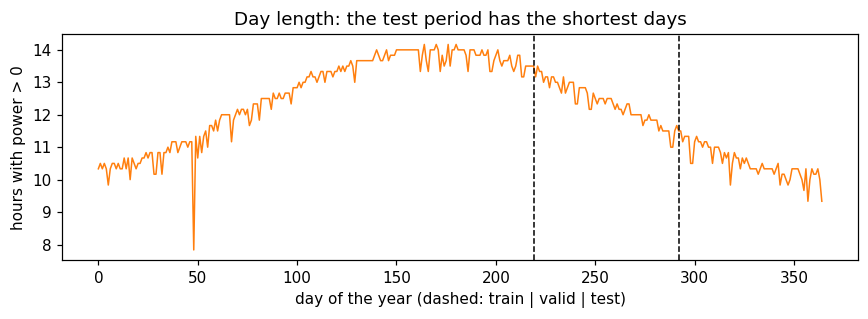

In [7]:
any_producing = (x > 0).any(axis=1).reshape(-1, STEPS_PER_DAY)   # (365 days, 144 steps)
day_hours = any_producing.sum(axis=1) / 6                         # 6 steps = 1 hour
print(f"production hours per day: shortest {day_hours.min():.1f} h, longest {day_hours.max():.1f} h")
print(f"mean in train {day_hours[:219].mean():.1f} h, valid {day_hours[219:292].mean():.1f} h, test {day_hours[292:].mean():.1f} h")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(day_hours, color="tab:orange", lw=1)
ax.axvline(train_end / STEPS_PER_DAY, color="k", ls="--", lw=1)
ax.axvline(valid_end / STEPS_PER_DAY, color="k", ls="--", lw=1)
ax.set_xlabel("day of the year (dashed: train | valid | test)")
ax.set_ylabel("hours with power > 0")
ax.set_title("Day length: the test period has the shortest days")
plt.tight_layout()
fig.savefig(FIGS / "solar_day_length.png")
plt.show()

## 6 · Daily pattern (compare with Figure 3 of the paper)

Autocorrelation at lag τ = correlation of the series with itself shifted by τ steps.
One day is 144 steps. The paper's Solar skip length was tuned in 2–64, i.e. never a full day.
Our horizon h = 24 steps is only 4 hours, so "same time yesterday" is far back in the window.

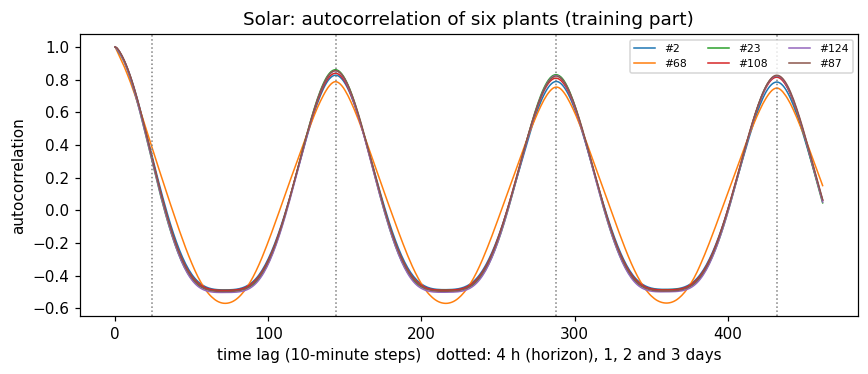

In [8]:
def autocorr(series, max_lag):
    """Autocorrelation for the lags 0, 1, ..., max_lag."""
    s = series - series.mean()              # centre the series around 0
    var = (s * s).sum()
    result = []
    for k in range(max_lag + 1):
        # multiply the series with itself shifted by k steps, add up, scale to -1 .. 1
        result.append((s[: len(s) - k] * s[k:]).sum() / var)
    return np.array(result)

max_lag = 3 * STEPS_PER_DAY + 30   # a bit more than three days
fig, ax = plt.subplots(figsize=(8, 3.5))
for j in rng.choice(n, size=6, replace=False):
    ax.plot(autocorr(x[:train_end, j], max_lag), lw=1, label=f"#{j}")
for lag in (24, 144, 288, 432):
    ax.axvline(lag, color="grey", ls=":", lw=1)
ax.set_xlabel("time lag (10-minute steps)   dotted: 4 h (horizon), 1, 2 and 3 days")
ax.set_ylabel("autocorrelation")
ax.set_title("Solar: autocorrelation of six plants (training part)")
ax.legend(fontsize=7, ncol=3)
plt.tight_layout()
fig.savefig(FIGS / "solar_autocorrelation.png")
plt.show()

In [9]:
# How strong are the patterns across ALL plants?
acf_all = np.array([autocorr(x[:train_end, j], 3 * STEPS_PER_DAY) for j in range(n)])
print(f"median autocorrelation at lag  24 steps (4 h, our horizon): {np.median(acf_all[:, 24]):.2f}")
print(f"median autocorrelation at lag  72 steps (12 h):             {np.median(acf_all[:, 72]):.2f}")
print(f"median autocorrelation at lag 144 steps (1 day):            {np.median(acf_all[:, 144]):.2f}")
print(f"median autocorrelation at lag 288 steps (2 days):           {np.median(acf_all[:, 288]):.2f}")
print(f"median autocorrelation at lag 432 steps (3 days):           {np.median(acf_all[:, 432]):.2f}")

median autocorrelation at lag  24 steps (4 h, our horizon): 0.32
median autocorrelation at lag  72 steps (12 h):             -0.49
median autocorrelation at lag 144 steps (1 day):            0.85
median autocorrelation at lag 288 steps (2 days):           0.82
median autocorrelation at lag 432 steps (3 days):           0.82


### What would a skip of 144 (one day) need?

The skip-GRU looks at every p-th output of the CNN. The CNN (kernel width 6) turns q input steps
into q − 6 + 1 outputs; our code keeps the last `(q - 6) // p` · p of them and cuts them into p
sequences of length `(q - 6) // p`. With p = 144, each skip sequence has one step per day, so
its length = how many days the window covers.

In [10]:
p = STEPS_PER_DAY
for q_try in (168, 294, 438, 582):
    steps = (q_try - 6) // p
    print(f"window q = {q_try:3d} ({q_try / STEPS_PER_DAY:.1f} days): skip sequence length {steps}")

window q = 168 (1.2 days): skip sequence length 1
window q = 294 (2.0 days): skip sequence length 2
window q = 438 (3.0 days): skip sequence length 3
window q = 582 (4.0 days): skip sequence length 4


With the default q = 168 the skip-GRU would see a single step: no sequence at all, so a skip of
144 is useless there. Every extra day in a skip sequence costs 144 more input steps, which is
why a one-day skip needs a long window (e.g. q = 438 for 3 days) and more GPU memory.

## 7 · Does the level change between training and test?

The paper says the neural part cannot follow changes in scale, so the linear AR part is needed
(Sec. 4.6, Fig. 6). Here the test period is autumn and early winter: shorter days and a lower
sun, so we expect **every** plant to produce less. That is a distribution shift, which is
exactly what RevIN is designed for.

test mean / train mean per plant: median 0.71 (min 0.62, max 0.83)
plants that produce less in test: 137 of 137
plants whose level changes by more than 20%: 123 of 137


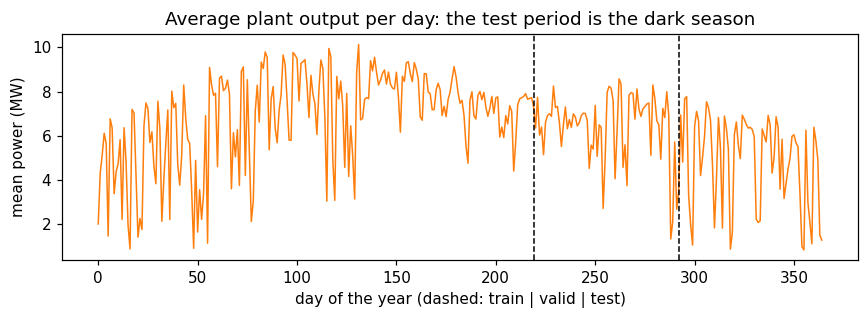

In [11]:
train_mean = x[:train_end].mean(axis=0)
test_mean = x[valid_end:].mean(axis=0)
ratio = test_mean / train_mean

print(f"test mean / train mean per plant: median {np.median(ratio):.2f} (min {ratio.min():.2f}, max {ratio.max():.2f})")
print(f"plants that produce less in test: {(ratio < 1).sum()} of {n}")
print(f"plants whose level changes by more than 20%: {((ratio < 0.8) | (ratio > 1.2)).sum()} of {n}")

# Daily energy of the average plant over the year: the season is clearly visible
daily = x.mean(axis=1).reshape(-1, STEPS_PER_DAY).mean(axis=1)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(daily, color="tab:orange", lw=1)
ax.axvline(train_end / STEPS_PER_DAY, color="k", ls="--", lw=1)
ax.axvline(valid_end / STEPS_PER_DAY, color="k", ls="--", lw=1)
ax.set_xlabel("day of the year (dashed: train | valid | test)")
ax.set_ylabel("mean power (MW)")
ax.set_title("Average plant output per day: the test period is the dark season")
plt.tight_layout()
fig.savefig(FIGS / "solar_level_shift.png")
plt.show()

## 8 · Normalisation as in the authors' code

`normalize=2`: divide each series by its maximum absolute value. The maximum is taken over the
**whole** series, test period included. That uses information from the future; we keep it so
our numbers are comparable with the paper, and note it in the report.
How often does that matter, i.e. how often is a plant's maximum in the test period?

In [12]:
scale = np.abs(x).max(axis=0)
scale[scale == 0] = 1                       # guard against division by zero
x_norm = x / scale
print(f"after scaling: min {x_norm.min():.2f}, max {x_norm.max():.2f}")

where_max = np.argmax(x, axis=0)
in_test = (where_max >= valid_end).sum()
print(f"plants whose overall maximum lies in the test period: {in_test} of {n}")

train_scale = np.abs(x[:train_end]).max(axis=0)
print(f"median (whole-series max / train-only max): {np.median(scale / train_scale):.2f}")

after scaling: min 0.00, max 1.00
plants whose overall maximum lies in the test period: 0 of 137
median (whole-series max / train-only max): 1.00


## 9 · Summary

| Question | Finding | Consequence for the project |
|---|---|---|
| Shape | 52,560 steps (10 min) × 137 plants = exactly one year, no missing values: matches the paper | Use the file as is |
| Split | train = days 0–219 (Jan–early Aug), valid = days 219–292, test = days 292–365 (late Oct–Dec) | The split is also a season split; about 31,300 training windows for q = 168, h = 24 |
| Scale | Plant maximum ranges from 8.8 to 88.9 MW; mean output differs by a factor of ~12 | Much smaller spread than Electricity (~19,000×), but per-series scaling still matters |
| Zeros | 55% of all values are 0; at 49.5% of steps every plant is 0 (night); no constant plants, also none in test | No series is dropped from CORR. Night is easy to predict, so errors come from daytime |
| Day length | Production hours per day 7.8–14.2 h; mean 12.6 h in train, 10.5 h in test | The test period has the shortest days: part of the season shift |
| Patterns | Median autocorrelation 0.85 at 144 steps (1 day), 0.82 at 2 and 3 days, −0.49 at 72 (12 h), only 0.32 at 24 (4 h, our horizon) | The useful cycle is one day = 144 steps, and it stays strong over several days |
| Skip of 144 | With q = 168 a skip sequence has `(168 − 6) // 144` = 1 step; 2 days needs q = 294, 3 days q = 438 | The paper's p ≤ 64 cannot see the daily cycle; a one-day skip needs a much longer window (optional task 6) |
| Level shift | Every plant produces less in test: median test/train ratio 0.71 (0.62–0.83); 123 of 137 change by > 20% | Strong distribution shift, far larger than in Electricity (median 0.99): RevIN has more to gain here |
| Normalisation | No plant has its maximum in the test period; whole-series max = train-only max (median ratio 1.00) | The authors' scaling leaks nothing on Solar; keep it for comparability |